# Prévisions météo des prochaines heures (MET Norway)

Table `weather_forecast` : prévisions MET Norway (Locationforecast 2.0), collectées toutes les 3 h et
toutes conservées. Ce notebook montre la **dernière prévision** pour chaque lieu : nébulosité par étage
et brouillard, les deux conditions qui empêchent de voir une aurore.

Mêmes prérequis que les autres notebooks (`data/clean` à jour depuis la branche `clean-data`).
Données : MET Norway, licence CC BY 4.0.

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

from auroracast.data import load

COLORS = {"tromso": "#2a78d6", "kiruna": "#eb6834", "rovaniemi": "#1baf7a"}
NAMES = {"tromso": "Tromsø", "kiruna": "Kiruna", "rovaniemi": "Rovaniemi"}
ORDER = ["tromso", "kiruna", "rovaniemi"]
MUTED, INK = "#52514e", "#0b0b0b"
SOURCE = "Source : MET Norway, Locationforecast 2.0 (CC BY 4.0) ; collecte AuroraCast"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c2",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": "#e7e6e1", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

fc = load("weather_forecast")
latest = fc[fc["issued_at"] == fc.groupby("location")["issued_at"].transform("max")]
hourly = latest[latest["step_hours"] == 1]
fc.groupby("location").agg(previsions=("issued_at", "nunique"), derniere=("issued_at", "max"),
                          jusqu_au=("target_time", "max"))

,previsions,derniere,jusqu_au
location,,,
kiruna,1,2026-10-29 08:30:21+00:00,2026-11-08 00:00:00+00:00
rovaniemi,1,2026-10-29 08:30:22+00:00,2026-11-08 00:00:00+00:00
tromso,1,2026-10-29 08:30:21+00:00,2026-11-08 00:00:00+00:00


## 1. Nébulosité totale et brouillard, heure par heure

Trait plein : nébulosité totale (0 % = ciel dégagé). Zone grisée : part de la zone couverte de
brouillard (visibilité sous 1 km). Une aurore n'est visible que si les deux sont bas, et de nuit.

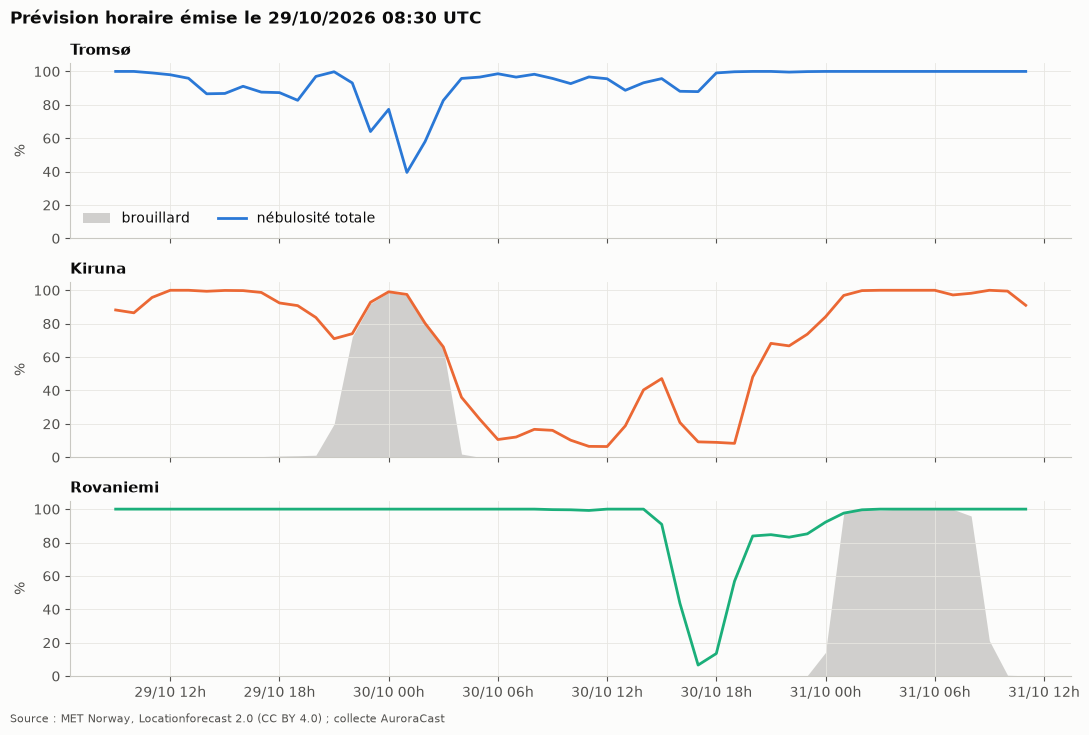

In [2]:
fig, axes = plt.subplots(3, 1, figsize=(11, 7.2), sharex=True, sharey=True)
for ax, loc in zip(axes, ORDER):
    g = hourly[hourly["location"] == loc]
    ax.fill_between(g["target_time"], 0, g["fog_pct"], color="#9b9a95", alpha=0.45, linewidth=0,
                    label="brouillard")
    ax.plot(g["target_time"], g["cloud_cover_pct"], color=COLORS[loc], linewidth=2,
            label="nébulosité totale")
    ax.set_title(NAMES[loc])
    ax.set_ylim(0, 105)
    ax.set_ylabel("%")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %Hh"))
axes[0].legend(frameon=False, loc="lower left", ncols=2)
issued = hourly["issued_at"].max().strftime("%d/%m/%Y %H:%M UTC")
fig.suptitle(f"Prévision horaire émise le {issued}", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.text(0.01, -0.01, SOURCE, fontsize=8, color=MUTED)
fig.tight_layout()
plt.show()

## 2. Nuages par étage

Les nuages bas (moins de 2 000 m) sont ceux qui bouchent le plus sûrement le ciel ; un voile de nuages
hauts (plus de 5 000 m) laisse parfois voir une aurore intense.

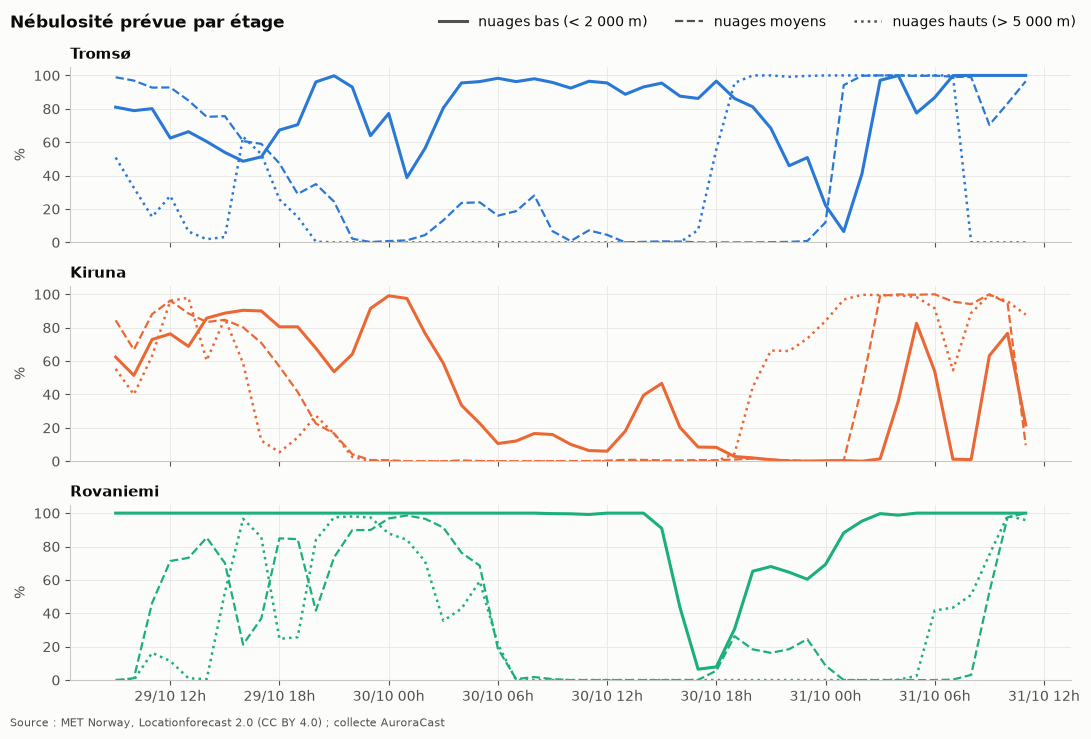

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(11, 7.2), sharex=True, sharey=True)
layers = [("cloud_low_pct", "bas (< 2 000 m)", "-", 2.2), ("cloud_medium_pct", "moyens", "--", 1.6),
          ("cloud_high_pct", "hauts (> 5 000 m)", ":", 1.8)]
for ax, loc in zip(axes, ORDER):
    g = hourly[hourly["location"] == loc]
    for col, label, style, width in layers:
        ax.plot(g["target_time"], g[col], color=COLORS[loc], linestyle=style, linewidth=width,
                label=f"nuages {label}")
    ax.set_title(NAMES[loc])
    ax.set_ylim(0, 105)
    ax.set_ylabel("%")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %Hh"))
handles = [plt.Line2D([], [], color=MUTED, linestyle=st, linewidth=w) for _, _, st, w in layers]
fig.legend(handles, [f"nuages {lab}" for _, lab, _, _ in layers], frameon=False, ncols=3,
           loc="upper right", bbox_to_anchor=(0.99, 0.995))
fig.suptitle("Nébulosité prévue par étage", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.text(0.01, -0.01, SOURCE, fontsize=8, color=MUTED)
fig.tight_layout()
plt.show()

## 3. Heures à ciel dégagé dans la prévision

Nombre d'heures prévues avec moins de 30 % de nuages et moins de 10 % de brouillard. Ce seuil est
provisoire : il sera fixé avec le modèle, et croisé avec la nuit noire (table astronomique à venir).

In [4]:
clear = hourly.assign(clear=(hourly["cloud_cover_pct"] < 30) & (hourly["fog_pct"].fillna(0) < 10))
clear.groupby("location").agg(heures_prevues=("clear", "size"), heures_degagees=("clear", "sum")) \
     .rename(index=NAMES)

,heures_prevues,heures_degagees
location,,
Kiruna,51,13
Rovaniemi,51,2
Tromsø,51,0
